# 共役勾配法を最適化問題から導出する

## 概要

共役勾配法（CG）は、実対称正定値行列を係数とする連立一次方程式を解く反復法である。二次関数の最小化から出発し、直線探索、探索方向の共役性、更新係数の順に導く。最後にPythonで最急降下法との違いと疎行列での動作を確認する。非線形共役勾配法と前処理は扱わない。

## 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、Matplotlibを使う。以下はNotebookのあるディレクトリで上から実行する。図は `105_nb_files` にSVG形式で保存し、出力にも埋め込む。表示する小数は有効数字3桁とし、内部の計算精度は落とさない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import numpy as np
import scipy
from scipy.sparse import diags
from scipy.sparse.linalg import cg, spsolve
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import Latex, SVG, display

print("環境: wa-src(3.14.6)")
print(f"Python: {platform.python_version()} / OS: {platform.system()}")
print(f"NumPy: {np.__version__}, SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")

OUT = Path("105_nb_files")
OUT.mkdir(exist_ok=True)

def sig(value):
    return f"{float(value):#.3g}"

np.set_printoptions(formatter={"float_kind": sig})
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})

def save_svg(fig, name):
    # 軸の小数も3桁に統一する。反復回数は整数で表示する。
    for ax in fig.axes:
        if ax.get_xlabel() == "Iteration":
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        elif ax.get_xscale() == "linear":
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: sig(v)))
        if ax.get_yscale() == "linear":
            ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: sig(v)))
    fig.tight_layout()
    path = OUT / name
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

環境: wa-src(3.14.6)
Python: 3.14.6 / OS: Darwin
NumPy: 2.5.4, SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 連立方程式を最小化問題に置き換える

$\mathbf{A}\in\mathbb{R}^{n\times n}$、$\mathbf{b},\mathbf{x}\in\mathbb{R}^n$とする。仮定は

$$
\mathbf{A}^{\mathsf T}=\mathbf{A},\qquad
\mathbf{v}^{\mathsf T}\mathbf{A}\mathbf{v}>0
\quad(\mathbf{v}\ne\mathbf{0})
$$

である。次の二次関数を考える。

$$
f(\mathbf{x})=\frac12\mathbf{x}^{\mathsf T}\mathbf{A}\mathbf{x}
-\mathbf{b}^{\mathsf T}\mathbf{x}
=\frac12\sum_{i=1}^n\sum_{j=1}^n A_{ij}x_ix_j-\sum_{i=1}^n b_ix_i.
$$

成分$x_\ell$で微分する。対称性により二つの和が一致する。

$$
\begin{aligned}
\frac{\partial f}{\partial x_\ell}
&=\frac12\sum_j A_{\ell j}x_j+\frac12\sum_i A_{i\ell}x_i-b_\ell\\
&=\sum_j A_{\ell j}x_j-b_\ell,\\
\nabla f(\mathbf{x})&=\mathbf{A}\mathbf{x}-\mathbf{b},\qquad
\nabla^2 f(\mathbf{x})=\mathbf{A}.
\end{aligned}
$$

ヘッセ行列が正定値なので$f$は狭義凸である。停留条件$\nabla f(\mathbf{x}_*)=\mathbf{0}$は$\mathbf{A}\mathbf{x}_*=\mathbf{b}$となり、この解が唯一の最小点である。誤差$\mathbf{e}=\mathbf{x}-\mathbf{x}_*$を代入しても確認できる。

$$
\begin{aligned}
f(\mathbf{x}_*+\mathbf{e})-f(\mathbf{x}_*)
&=\frac12\mathbf{x}_*^{\mathsf T}\mathbf{A}\mathbf{e}
+\frac12\mathbf{e}^{\mathsf T}\mathbf{A}\mathbf{x}_*
+\frac12\mathbf{e}^{\mathsf T}\mathbf{A}\mathbf{e}-\mathbf{b}^{\mathsf T}\mathbf{e}\\
&=\mathbf{e}^{\mathsf T}(\mathbf{A}\mathbf{x}_*-\mathbf{b})
+\frac12\mathbf{e}^{\mathsf T}\mathbf{A}\mathbf{e}\\
&=\frac12\mathbf{e}^{\mathsf T}\mathbf{A}\mathbf{e}
=\frac12\|\mathbf{e}\|_{\mathbf{A}}^2\ge0.
\end{aligned}
$$

ここで$\|\mathbf{e}\|_{\mathbf{A}}=\sqrt{\mathbf{e}^{\mathsf T}\mathbf{A}\mathbf{e}}$である。以降、残差を$\mathbf{r}_k=\mathbf{b}-\mathbf{A}\mathbf{x}_k=-\nabla f(\mathbf{x}_k)$と書く。私は、この符号を確認してから更新式を読む方が理解しやすいと感じる。

## 2. 直線上で最小化する

非零の方向$\mathbf{p}_k$に沿って$\mathbf{x}_{k+1}=\mathbf{x}_k+\alpha_k\mathbf{p}_k$と進む。$\phi(\alpha)=f(\mathbf{x}_k+\alpha\mathbf{p}_k)$を展開すると、

$$
\begin{aligned}
\phi(\alpha)
&=\frac12\mathbf{x}_k^{\mathsf T}\mathbf{A}\mathbf{x}_k
+\frac\alpha2(\mathbf{x}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k
+\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{x}_k)
+\frac{\alpha^2}{2}\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k
-\mathbf{b}^{\mathsf T}\mathbf{x}_k-\alpha\mathbf{b}^{\mathsf T}\mathbf{p}_k\\
&=f(\mathbf{x}_k)-\alpha\mathbf{r}_k^{\mathsf T}\mathbf{p}_k
+\frac{\alpha^2}{2}\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k,\\
\phi'(\alpha)&=-\mathbf{r}_k^{\mathsf T}\mathbf{p}_k
+\alpha\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k.
\end{aligned}
$$

二階微分は正なので、$\phi'(\alpha_k)=0$から

$$
\alpha_k=\frac{\mathbf{r}_k^{\mathsf T}\mathbf{p}_k}
{\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k},\qquad
\mathbf{r}_{k+1}=\mathbf{r}_k-\alpha_k\mathbf{A}\mathbf{p}_k
$$

を得る。したがって$\mathbf{p}_k^{\mathsf T}\mathbf{r}_{k+1}=\mathbf{p}_k^{\mathsf T}\mathbf{r}_k-\alpha_k\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k=0$である。

毎回$\mathbf{p}_k=\mathbf{r}_k$と選ぶと最急降下法になり、$\alpha_k=\mathbf{r}_k^{\mathsf T}\mathbf{r}_k/(\mathbf{r}_k^{\mathsf T}\mathbf{A}\mathbf{r}_k)$となる。次の図は二次元の等高線と、最初の直線探索を示す。

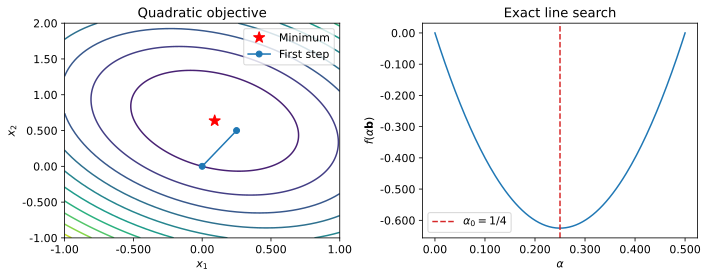

In [2]:
A = np.array([[4, 1], [1, 3]], dtype=float)
b = np.array([1, 2], dtype=float)
x_star = np.linalg.solve(A, b)

def objective(x):
    return x @ A @ x / 2 - b @ x

u, v = np.meshgrid(np.linspace(-1, 1, 180), np.linspace(-1, 2, 180))
F = (4 * u**2 + 2 * u * v + 3 * v**2) / 2 - u - 2 * v
alpha = np.linspace(0, 1 / 2, 150)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].contour(u, v, F, levels=12, cmap="viridis")
axes[0].plot(*x_star, "r*", ms=12, label="Minimum")
axes[0].plot([0, 1 / 4], [0, 1 / 2], "o-", label="First step")
axes[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Quadratic objective")
axes[0].set_xticks([-1, -1 / 2, 0, 1 / 2, 1])
axes[0].legend()
axes[1].plot(alpha, [objective(t * b) for t in alpha])
axes[1].axvline(1 / 4, ls="--", color="tab:red", label=r"$\alpha_0=1/4$")
axes[1].set(xlabel=r"$\alpha$", ylabel=r"$f(\alpha\mathbf{b})$", title="Exact line search")
axes[1].legend()
save_svg(fig, "01_objective.svg")

## 3. 過去の最小化を保つ方向

最急降下法では、後の更新によって以前の方向の停留条件が崩れることがある。これを防ぐため、異なる方向に

$$
\mathbf{p}_i^{\mathsf T}\mathbf{A}\mathbf{p}_j=0\quad(i\ne j)
$$

を課す。これを$\mathbf{A}$共役という。通常の直交$\mathbf{p}_i^{\mathsf T}\mathbf{p}_j=0$とは異なる。

$S_k=\operatorname{span}\{\mathbf{p}_0,\ldots,\mathbf{p}_{k-1}\}$とする。$\mathbf{x}_k$が$\mathbf{x}_0+S_k$で最小なら、各方向の微分が零なので$\mathbf{p}_i^{\mathsf T}\mathbf{r}_k=0$（$i<k$）である。新しい方向も過去の方向と共役なら、

$$
\mathbf{p}_i^{\mathsf T}\mathbf{r}_{k+1}
=\mathbf{p}_i^{\mathsf T}\mathbf{r}_k
-\alpha_k\mathbf{p}_i^{\mathsf T}\mathbf{A}\mathbf{p}_k=0\quad(i<k).
$$

直線探索により$i=k$でも零になる。よって$\mathbf{x}_{k+1}$は拡大した空間$\mathbf{x}_0+S_{k+1}$での最小点である。

## 4. 共役な方向を残差から作る

初期方向を$\mathbf{p}_0=\mathbf{r}_0$とし、

$$
\mathbf{p}_{k+1}=\mathbf{r}_{k+1}+\beta_k\mathbf{p}_k
$$

の形を考える。以下は丸め誤差のない計算で、まだ残差が零になっていない場合の導出である。

### ステップ幅の分子

上の漸化式から、残差と方向の張る空間は一致する。実際、$\mathbf{r}_k=\mathbf{p}_k-\beta_{k-1}\mathbf{p}_{k-1}$であり、逆向きには$\mathbf{p}_k$を過去の残差で順に表せる。前節の直交条件より、$k\ge1$では

$$
\mathbf{r}_k^{\mathsf T}\mathbf{p}_k
=\mathbf{r}_k^{\mathsf T}(\mathbf{r}_k+\beta_{k-1}\mathbf{p}_{k-1})
=\mathbf{r}_k^{\mathsf T}\mathbf{r}_k.
$$

$k=0$でも同じである。したがって$\alpha_k=\mathbf{r}_k^{\mathsf T}\mathbf{r}_k/(\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k)$となる。また$\mathbf{r}_{k+1}$は$S_{k+1}$に直交するため、そこに属する$\mathbf{r}_0,\ldots,\mathbf{r}_k$とも直交する。

### $\beta_k$の導出

直前の方向との共役条件を代入する。

$$
\begin{aligned}
0&=\mathbf{p}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_k
=\mathbf{r}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_k
+\beta_k\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k,\\
\beta_k&=-\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_k}
{\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k}.
\end{aligned}
$$

残差更新を変形した$\mathbf{A}\mathbf{p}_k=(\mathbf{r}_k-\mathbf{r}_{k+1})/\alpha_k$を使うと、

$$
\begin{aligned}
\mathbf{r}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_k
&=\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_k-
\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{k+1}}{\alpha_k}
=-\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{k+1}}{\alpha_k},\\
\beta_k&=\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{k+1}}
{\alpha_k\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k}
=\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{k+1}}
{\mathbf{r}_k^{\mathsf T}\mathbf{r}_k}.
\end{aligned}
$$

直前だけでなく、$j<k$の方向との共役性も必要である。過去の共役性と残差の直交性から、

$$
\begin{aligned}
\mathbf{p}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_j
&=\mathbf{r}_{k+1}^{\mathsf T}\mathbf{A}\mathbf{p}_j
+\beta_k\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_j\\
&=\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_j
-\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{j+1}}{\alpha_j}+0=0.
\end{aligned}
$$

$\mathbf{p}_0=\mathbf{r}_0$を出発点に、最小化、残差の直交性、新しい方向の共役性が帰納的に保たれる。更新式をまとめる。

In [3]:
# 重要な式をLaTeX形式で出力欄に表示する。
display(Latex(r"\(\displaystyle \begin{aligned}"
    r"\alpha_k&=\frac{\mathbf{r}_k^{\mathsf T}\mathbf{r}_k}"
    r"{\mathbf{p}_k^{\mathsf T}\mathbf{A}\mathbf{p}_k},\\"
    r"\mathbf{x}_{k+1}&=\mathbf{x}_k+\alpha_k\mathbf{p}_k,\\"
    r"\mathbf{r}_{k+1}&=\mathbf{r}_k-\alpha_k\mathbf{A}\mathbf{p}_k,\\"
    r"\beta_k&=\frac{\mathbf{r}_{k+1}^{\mathsf T}\mathbf{r}_{k+1}}"
    r"{\mathbf{r}_k^{\mathsf T}\mathbf{r}_k},\\"
    r"\mathbf{p}_{k+1}&=\mathbf{r}_{k+1}+\beta_k\mathbf{p}_k"
    r"\end{aligned}\)"))

<IPython.core.display.Latex object>

非零の共役方向は一次独立である。$\sum_i c_i\mathbf{p}_i=\mathbf{0}$の両辺に$\mathbf{p}_j^{\mathsf T}\mathbf{A}$を掛けると$c_j\mathbf{p}_j^{\mathsf T}\mathbf{A}\mathbf{p}_j=0$となり、正定値性より$c_j=0$を得る。従って厳密計算では高々$n$反復で解に到達する。

生成される空間は、収束するまで

$$
S_k=\mathcal{K}_k(\mathbf{A},\mathbf{r}_0)
=\operatorname{span}\{\mathbf{r}_0,\mathbf{A}\mathbf{r}_0,
\ldots,\mathbf{A}^{k-1}\mathbf{r}_0\}
$$

となる。更新式に現れる行列積を順に追うと包含関係が得られ、独立な方向が$k$本あるため両者の次元も一致する。CGはこの空間上で$f$、すなわち誤差の$\mathbf{A}$ノルムを最小化する。残差のユークリッドノルム$\|\mathbf{r}_k\|_2$を最小化するわけではなく、これは反復途中に増える場合もある。

## 5. 二次元の例を手で計算する

最初の図と同じ行列で$\mathbf{x}_0=\mathbf{0}$とする。

$$
\mathbf{A}=\begin{pmatrix}4&1\\1&3\end{pmatrix},\quad
\mathbf{b}=\begin{pmatrix}1\\2\end{pmatrix},\quad
\mathbf{p}_0=\mathbf{r}_0=\mathbf{b}.
$$

この行列は$A_{11}=4>0$、$\det\mathbf{A}=11>0$なので正定値である。最初の更新は

$$
\begin{aligned}
\mathbf{A}\mathbf{p}_0&=\begin{pmatrix}6\\7\end{pmatrix},&
\alpha_0&=\frac{1^2+2^2}{1\cdot6+2\cdot7}=\frac14,\\
\mathbf{x}_1&=\frac14\begin{pmatrix}1\\2\end{pmatrix},&
\mathbf{r}_1&=\begin{pmatrix}1\\2\end{pmatrix}
-\frac14\begin{pmatrix}6\\7\end{pmatrix}
=\begin{pmatrix}-1/2\\1/4\end{pmatrix}.
\end{aligned}
$$

次の方向とステップ幅は

$$
\begin{aligned}
\beta_0&=\frac{1/4+1/16}{5}=\frac1{16},\\
\mathbf{p}_1&=\begin{pmatrix}-1/2\\1/4\end{pmatrix}
+\frac1{16}\begin{pmatrix}1\\2\end{pmatrix}
=\frac1{16}\begin{pmatrix}-7\\6\end{pmatrix},\\
\mathbf{A}\mathbf{p}_1&=\frac1{16}\begin{pmatrix}-22\\11\end{pmatrix},\\
\alpha_1&=\frac{5/16}{(154+66)/256}=\frac{5/16}{55/64}=\frac4{11},\\
\mathbf{x}_2&=\begin{pmatrix}1/4\\1/2\end{pmatrix}
+\frac4{11}\frac1{16}\begin{pmatrix}-7\\6\end{pmatrix}
=\begin{pmatrix}1/11\\7/11\end{pmatrix}.
\end{aligned}
$$

$\mathbf{A}\mathbf{x}_2=(1,2)^{\mathsf T}=\mathbf{b}$となる。また$\mathbf{r}_0^{\mathsf T}\mathbf{r}_1=-1/2+2/4=0$、$\mathbf{p}_0^{\mathsf T}\mathbf{A}\mathbf{p}_1=(-22+22)/16=0$である。

## 6. Pythonで更新式を実装する

次の関数は実対称正定値行列を前提とし、通常の配列と疎行列を受け付ける。`use_cg=False` では方向を残差に戻して最急降下法にする。初期点が既に解の場合も、除算の前に停止する。学習用に履歴を保存するため追加メモリは反復数$k$に対して$O(kn)$である。履歴を保存しないCGなら、行列の保存領域を除いて$O(n)$で済む。

In [4]:
def solve_quadratic(A, b, x0=None, *, use_cg=True,
                    rtol=1.00e-10, atol=0.00, maxiter=1000):
    """CGまたは最急降下法を実行し、解・履歴・収束判定を返す。"""
    x = np.zeros_like(b, dtype=float) if x0 is None else np.array(x0, dtype=float)
    r = b - A @ x
    p = r.copy()
    xs, rs, ps = [x.copy()], [r.copy()], []
    threshold = max(atol, rtol * np.linalg.norm(b))
    rr = r @ r

    for _ in range(maxiter):
        if np.sqrt(rr) <= threshold:
            break
        Ap = A @ p
        curvature = p @ Ap
        if curvature <= 0:
            raise ValueError("探索方向の曲率が正でない")
        ps.append(p.copy())
        alpha = rr / curvature
        x = x + alpha * p
        r = r - alpha * Ap
        rr_new = r @ r
        beta = rr_new / rr if use_cg else 0
        p = r + beta * p
        rr = rr_new
        xs.append(x.copy())
        rs.append(r.copy())

    # 漸化式の残差と真の残差は丸め誤差でずれるため、最後は再計算する。
    converged = np.linalg.norm(b - A @ x) <= threshold
    history = {"x": np.array(xs), "r": np.array(rs), "p": np.array(ps)}
    return x, history, bool(converged)

x, small, ok = solve_quadratic(A, b)
pprint({"解": x, "反復数": len(small["p"]), "収束": ok,
        "真の残差ノルム": sig(np.linalg.norm(b - A @ x))})
assert ok and np.allclose(x, [1 / 11, 7 / 11], rtol=1.00e-12, atol=1.00e-14)

{'反復数': 2, '収束': True, '真の残差ノルム': '0.00', '解': array([0.0909, 0.636])}


### 経路と収束の比較

違いを見やすくするため、ここでは$\mathbf{A}=\begin{pmatrix}10&9\\9&10\end{pmatrix}$、$\mathbf{b}=(1,2)^{\mathsf T}$、$\mathbf{x}_0=(-2,2)^{\mathsf T}$を使う。固有値は$1,19$である。経路図の最急降下法は最初の18反復のみ、収束図は全反復を示す。SDは最急降下法の略である。

{'反復数': 222, '収束': True, '方法': 'SD'}
{'反復数': 2, '収束': True, '方法': 'CG'}


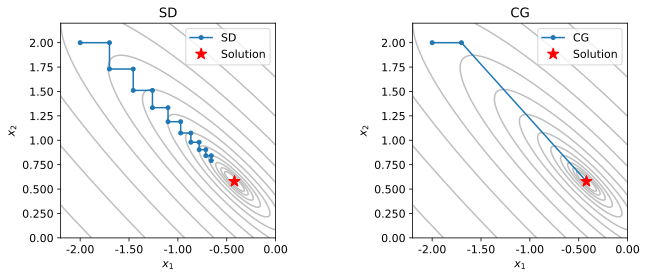

In [5]:
A_path = np.array([[10, 9], [9, 10]], dtype=float)
x0 = np.array([-2, 2], dtype=float)
reference = np.linalg.solve(A_path, b)
runs = {}
for label, use_cg in [("SD", False), ("CG", True)]:
    _, h, success = solve_quadratic(A_path, b, x0, use_cg=use_cg)
    runs[label] = h
    pprint({"方法": label, "反復数": len(h["p"]), "収束": success})

u, v = np.meshgrid(np.linspace(-2.2, 0, 180), np.linspace(0, 2.2, 180))
e1, e2 = u - reference[0], v - reference[1]
gap = (10 * e1**2 + 18 * e1 * e2 + 10 * e2**2) / 2
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, h) in zip(axes, runs.items()):
    path = h["x"][:19]
    ax.contour(u, v, gap, levels=np.geomspace(1.00e-2, 20, 13), colors="0.75")
    ax.plot(path[:, 0], path[:, 1], "o-", ms=4, label=label)
    ax.plot(*reference, "r*", ms=12, label="Solution")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title=label, aspect="equal")
    ax.legend()
save_svg(fig, "02_paths.svg")

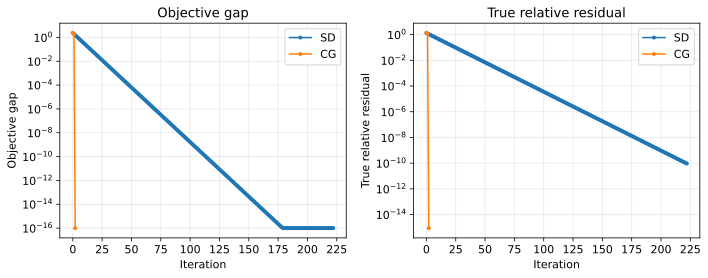

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, h in runs.items():
    errors = h["x"] - reference
    # f(x)-f(x*)の差し引きによる桁落ちを避ける。
    energy = np.einsum("ki,ij,kj->k", errors, A_path, errors) / 2
    residual = np.linalg.norm(b - h["x"] @ A_path.T, axis=1) / np.linalg.norm(b)
    axes[0].semilogy(np.maximum(energy, 1.00e-16), ".-", label=label)
    axes[1].semilogy(np.maximum(residual, 1.00e-16), ".-", label=label)
for ax, title in zip(axes, ["Objective gap", "True relative residual"]):
    ax.set(xlabel="Iteration", ylabel=title, title=title)
    ax.grid(alpha=0.300)
    ax.legend()
save_svg(fig, "03_convergence.svg")

目的関数の差は$\frac12(\mathbf{x}_k-\mathbf{x}_*)^{\mathsf T}\mathbf{A}(\mathbf{x}_k-\mathbf{x}_*)$から計算した。対数グラフでは零も表示できるよう、$10^{-16}$未満を描画時だけ$10^{-16}$に置く。経路ではCGが2反復で解に到達する一方、最急降下法は方向を変えながら進む。

### 直交性と共役性を数値で確認する

六次元の対角行列でも確認する。ヒートマップは正規化した内積の絶対値であり、残差では$|\mathbf{r}_i^{\mathsf T}\mathbf{r}_j|/(\|\mathbf{r}_i\|_2\|\mathbf{r}_j\|_2)$、方向では$|\mathbf{p}_i^{\mathsf T}\mathbf{A}\mathbf{p}_j|/(\|\mathbf{p}_i\|_{\mathbf{A}}\|\mathbf{p}_j\|_{\mathbf{A}})$を示す。収束後のほぼ零の残差は正規化から除く。

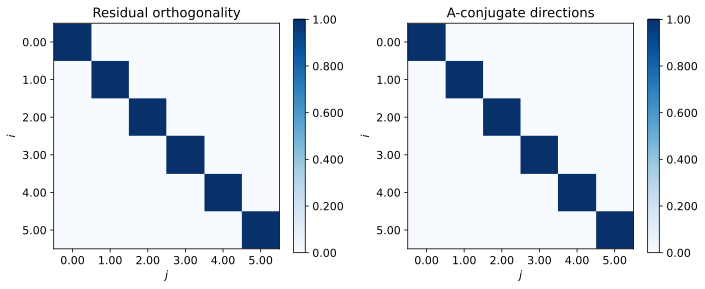

{'非対角成分の最大絶対値': ['5.46e-14', '5.78e-14']}


In [7]:
A_check = np.diag(np.arange(1, 7, dtype=float))
b_check = np.random.default_rng(105).normal(size=6)
_, h, ok = solve_quadratic(A_check, b_check, rtol=1.00e-12)
R, P = h["r"][:-1], h["p"]

def normalize_gram(G):
    scale = np.sqrt(np.diag(G))
    return G / np.outer(scale, scale)

grams = [normalize_gram(R @ R.T), normalize_gram(P @ A_check @ P.T)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, G, title in zip(axes, grams, ["Residual orthogonality", "A-conjugate directions"]):
    im = ax.imshow(np.abs(G), vmin=0, vmax=1, cmap="Blues")
    ax.set(title=title, xlabel="$j$", ylabel="$i$")
    ax.set_xticks(range(len(G)))
    ax.set_yticks(range(len(G)))
    fig.colorbar(im, ax=ax)
save_svg(fig, "04_orthogonality.svg")
pprint({"非対角成分の最大絶対値": [sig(np.max(np.abs(G - np.eye(len(G)))))
                                      for G in grams]})
assert ok and all(np.max(np.abs(G - np.eye(len(G)))) < 1.00e-10 for G in grams)

### 条件数を変える

正定値行列の条件数は$\kappa_2(\mathbf{A})=\lambda_{\max}/\lambda_{\min}$である。次は固有値を$1$から$\kappa$まで等間隔に並べ、同じ右辺で比較する。条件数が大きいと収束が遅くなりやすいが、反復数は固有値の分布と右辺にも依存する。浮動小数点計算では直交性が失われ、高々$n$反復という保証もそのままは成立しない。

{'反復数': 32, '収束': True, '条件数': 10}
{'反復数': 47, '収束': True, '条件数': 100}
{'反復数': 51, '収束': True, '条件数': 1000}


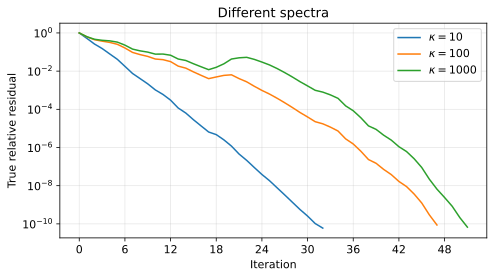

In [8]:
n = 60
rhs = np.random.default_rng(105).normal(size=n)
fig, ax = plt.subplots(figsize=(7, 4))
for kappa in [10, 100, 1000]:
    spectrum = np.linspace(1, kappa, n)
    D = diags(spectrum, format="csr")
    _, h, ok = solve_quadratic(D, rhs)
    residual = np.linalg.norm(rhs - h["x"] * spectrum, axis=1) / np.linalg.norm(rhs)
    ax.semilogy(np.maximum(residual, 1.00e-16), label=fr"$\kappa={kappa}$")
    pprint({"条件数": kappa, "反復数": len(h["p"]), "収束": ok})
ax.set(xlabel="Iteration", ylabel="True relative residual", title="Different spectra")
ax.grid(alpha=0.300)
ax.legend()
save_svg(fig, "05_condition_number.svg")

## 7. 疎行列をSciPyと比較する

対角成分が$2$、上下の隣接成分が$-1$の三重対角行列を使う。この行列は

$$
\mathbf{v}^{\mathsf T}\mathbf{A}\mathbf{v}
=2\sum_{i=1}^n v_i^2-2\sum_{i=1}^{n-1}v_iv_{i+1}
=v_1^2+\sum_{i=1}^{n-1}(v_{i+1}-v_i)^2+v_n^2>0
\quad(\mathbf{v}\ne\mathbf{0})
$$

なので正定値である。CGの主要な計算は行列とベクトルの積であり、逆行列を作らない。非零要素数を$\operatorname{nnz}(\mathbf{A})$とすると、各反復の計算量は$O(\operatorname{nnz}(\mathbf{A})+n)$である。

[SciPyの`cg`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.cg.html)は$\|\mathbf{b}-\mathbf{A}\mathbf{x}\|_2\le\max(\mathrm{rtol}\|\mathbf{b}\|_2,\mathrm{atol})$を停止基準とし、`info=0`が収束を示す。以下では真の残差も再計算する。相対残差と解の相対誤差は別の量なので、直接法`spsolve`の解とも比較する。

{'SciPyのinfo': 0,
 'SciPyの反復数': 120,
 '直接法に対する相対誤差': '9.70e-15',
 '真の相対残差': '1.02e-13',
 '自作CGの反復数': 120,
 '自作CGの収束': True}


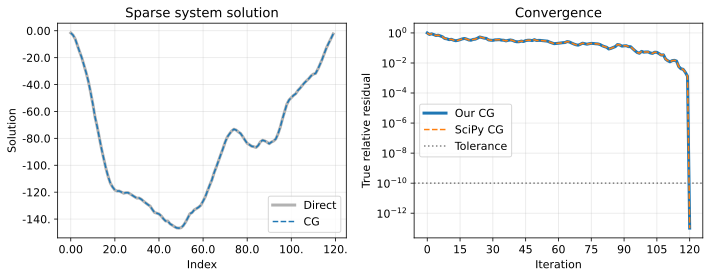

停止条件・解の一致・零残差の確認に成功した。


In [9]:
n = 120
A_sparse = diags([-np.ones(n - 1), 2 * np.ones(n), -np.ones(n - 1)],
                 offsets=[-1, 0, 1], format="csr")
rhs = np.random.default_rng(105).normal(size=n)
rtol = 1.00e-10
solution, h, ok = solve_quadratic(A_sparse, rhs, rtol=rtol)
norm_b = np.linalg.norm(rhs)
scipy_residuals = [1]

def record_residual(xk):
    scipy_residuals.append(np.linalg.norm(rhs - A_sparse @ xk) / norm_b)

scipy_solution, info = cg(A_sparse, rhs, rtol=rtol, atol=0.00,
                         maxiter=1000, callback=record_residual)
direct = spsolve(A_sparse, rhs)
true_residuals = np.linalg.norm(rhs[:, None] - A_sparse @ h["x"].T, axis=0) / norm_b
relative_error = np.linalg.norm(solution - direct) / np.linalg.norm(direct)
pprint({"自作CGの反復数": len(h["p"]), "自作CGの収束": ok,
        "SciPyのinfo": info, "SciPyの反復数": len(scipy_residuals) - 1,
        "真の相対残差": sig(true_residuals[-1]),
        "直接法に対する相対誤差": sig(relative_error)})

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(direct, label="Direct", lw=3, color="0.7")
axes[0].plot(solution, "--", label="CG")
axes[0].set(xlabel="Index", ylabel="Solution", title="Sparse system solution")
axes[1].semilogy(np.maximum(true_residuals, 1.00e-16), label="Our CG", lw=3)
axes[1].semilogy(np.maximum(scipy_residuals, 1.00e-16), "--", label="SciPy CG")
axes[1].axhline(rtol, color="0.5", ls=":", label="Tolerance")
axes[1].set(xlabel="Iteration", ylabel="True relative residual", title="Convergence")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.300)
save_svg(fig, "06_sparse_system.svg")

# 停止基準、別の解法との一致、初期残差が零の場合を確認する。
assert ok and info == 0 and true_residuals[-1] <= rtol
assert np.linalg.norm(rhs - A_sparse @ scipy_solution) / norm_b <= rtol
assert relative_error < 1.00e-9
assert np.allclose(solution, scipy_solution, rtol=1.00e-9, atol=1.00e-10)
_, zero_history, zero_ok = solve_quadratic(A, np.zeros(2))
assert zero_ok and len(zero_history["p"]) == 0
print("停止条件・解の一致・零残差の確認に成功した。")

## 結論

この記事では、正定値二次関数の最小化から共役勾配法の更新式を導き、Pythonで経路、直交性、収束を確認した。

直線探索でステップ幅を決め、過去の探索方向との共役性で既に満たした停留条件を保つ。この二つから残差の直交性と$\beta_k$の式が得られる。厳密計算では高々$n$反復で終了するが、実装では許容誤差と最大反復数を指定し、真の残差を確認する必要がある。

参考文献：J. R. Shewchuk, [An Introduction to the Conjugate Gradient Method Without the Agonizing Pain](https://people.eecs.berkeley.edu/~jrs/papers/cg.pdf), 1994, 第3・7・8節。部分空間での最小化はStanford EE364b [Conjugate Gradient Method](https://web.stanford.edu/class/ee364b/lectures/conj_grad_slides.pdf)も参照した。